# 03 · Final test and report

**Katip lab, notebook 3 of 3.** About 5 minutes.

This is the only notebook that reads **Wiki NER test**. Run it once, after notebook 2 has chosen a
configuration. Re-running it is fine (the numbers will be identical), but changing anything in
notebook 2 *because of* what you see here would invalidate the test.

It produces:

* the head-to-head table: published Tiny vs Katip Tiny-R (the retrained model), with 95% CIs,
* paired significance tests on the same names,
* a size vs real-text accuracy chart (the "small model" story),
* an automatic PASS / FAIL for each pre-registered hypothesis,
* `results/REPORT.md`, a short write-up you can paste into the README or a blog post.

In [1]:
import json, time, statistics
import pandas as pd
import matplotlib.pyplot as plt
import katiplab as K

prereg = json.loads((K.RESULTS / "02_prereg.json").read_text())
sel = json.loads((K.RESULTS / "02_selected.json").read_text())
print("pre-registered:", prereg["written_utc"]); print("selected:", sel)

test_sets = {"wiki test": K.load_wiki("test"), "blind": K.load_synth("blind"),
             "heldout": K.load_synth("heldout"), "negatives": K.load_synth("negatives")}

pre-registered: 2026-11-12T01:38:33+00:00
selected: {'N': 17967, 'trust': 0.5, 'dev_f2': 0.5243, 'heldout_recall': 1.0, 'seeds': [0], 'model_dirs': ['lab/runs/tiny_real17967_seed0']}


## 3.1 · Score on the sealed test

The new model is scored once per seed, and the significance test uses seed 0 (the model you would
ship). If notebook 2 chose a trust setting, the published model is also scored with that same
setting, as a **control**: it shows how much of the gain comes from the new model and how much from
the setting alone.

In [2]:
pub = K.Tagger(K.TINY)
new = [K.Tagger(K.ROOT / d) for d in sel["model_dirs"]]
systems = {
    "Rules (0.3 MB)": K.rules(),
    "Tiny, published": K.pipeline(pub),
    **({f"Tiny, published, trust {sel['trust']} (control)": K.pipeline(pub, trust=sel["trust"])} if sel["trust"] else {}),
    **{f"Tiny-R seed {i}": K.pipeline(t, trust=sel["trust"]) for i, t in enumerate(new)},
}
bert = None
if (K.BERTURK / "onnx" / "model_quantized.onnx").exists():
    bert = K.Tagger(K.BERTURK); systems["BERTurk pipeline (110.8 MB)"] = K.pipeline(bert, trust=0.9)
T = {name: K.evaluate(name, det, test_sets) for name, det in systems.items()}

rows = []
for name, by in T.items():
    row = {"system": name}
    for s, r in by.items():
        if s == "negatives": row["false names, name-free"] = r["false"]; continue
        row[f"{s} recall"] = f"{r['recall']:.1%} [{r['recall_ci'][0]:.1%}–{r['recall_ci'][1]:.1%}]"
        row[f"{s} precision"] = f"{r['precision']:.1%}"
    row["ms/doc (wiki)"] = round(by["wiki test"]["ms_per_doc"], 1)
    rows.append(row)
pd.DataFrame(rows).set_index("system")

,wiki test recall,wiki test precision,blind recall,blind precision,heldout recall,heldout precision,"false names, name-free",ms/doc (wiki)
system,,,,,,,,
Rules (0.3 MB),15.0% [11.0%–19.3%],71.6%,98.4% [96.4%–99.7%],100.0%,95.3% [91.8%–98.2%],100.0%,2,0.3
"Tiny, published",14.8% [11.1%–18.9%],69.6%,99.7% [99.1%–100.0%],100.0%,97.5% [94.8%–99.6%],100.0%,2,0.7
"Tiny, published, trust 0.5 (control)",34.4% [29.9%–39.0%],28.9%,99.7% [99.1%–100.0%],92.9%,99.3% [97.7%–100.0%],100.0%,39,0.7
Tiny-R seed 0,55.5% [51.2%–60.1%],61.2%,99.5% [98.6%–100.0%],98.3%,100.0% [100.0%–100.0%],100.0%,2,0.6
BERTurk pipeline (110.8 MB),40.7% [35.8%–45.3%],83.7%,100.0% [100.0%–100.0%],99.7%,100.0% [100.0%–100.0%],100.0%,2,16.5


## 3.2 · Is the difference real?

Two tests on the **same gold names**, published Tiny (A) vs Tiny-R seed 0 (B):

* **paired bootstrap** over documents: the 95% interval of the recall difference,
* **McNemar's exact test**: looks only at names one system found and the other missed.

In [3]:
A = T["Tiny, published"]; B = T["Tiny-R seed 0"]
sig = {}
for s in ("wiki test", "blind", "heldout"):
    sig[s] = K.paired_bootstrap(A[s]["_rows"][0], B[s]["_rows"][0])
    d = sig[s]
    print(f"{s:10} recall change {100 * d['diff']:+.1f} points  95% CI [{100 * d['ci'][0]:+.1f}, {100 * d['ci'][1]:+.1f}]  "
          f"found only by new: {d['only_b']}, only by old: {d['only_a']}, McNemar p = {d['p_mcnemar']:.2g}")

wiki test  recall change +40.7 points  95% CI [+35.9, +45.5]  found only by new: 269, only by old: 3, McNemar p = 8.8e-76
blind      recall change -0.3 points  95% CI [-0.9, +0.0]  found only by new: 0, only by old: 1, McNemar p = 1
heldout    recall change +2.5 points  95% CI [+0.4, +5.4]  found only by new: 7, only by old: 0, McNemar p = 0.016


## 3.3 · Size vs accuracy on real text

The selling point in one picture: what each megabyte buys on text Katip was not designed around.

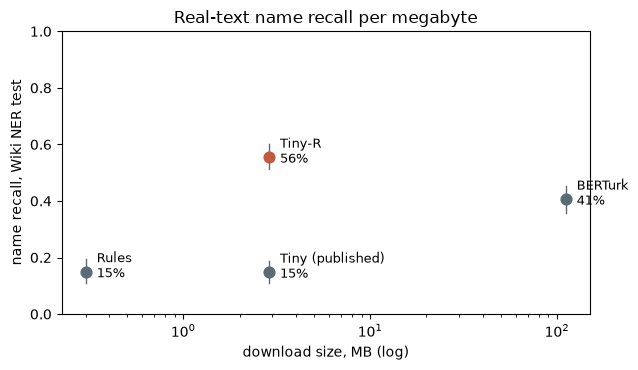

In [4]:
pts = [("Rules", 0.3, T["Rules (0.3 MB)"]), ("Tiny (published)", 0.3 + pub.size_mb, T["Tiny, published"]),
       ("Tiny-R", 0.3 + new[0].size_mb, T["Tiny-R seed 0"])]
if bert: pts.append(("BERTurk", 0.3 + bert.size_mb, T["BERTurk pipeline (110.8 MB)"]))
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for label, mb, r in pts:
    ax.scatter(mb, r["wiki test"]["recall"], s=60, color="#c2593f" if label == "Tiny-R" else "#5b6b73", zorder=3)
    lo, hi = r["wiki test"]["recall_ci"]; ax.plot([mb, mb], [lo, hi], color="#5b6b73", lw=1)
    ax.annotate(f"{label}\n{r['wiki test']['recall']:.0%}", (mb, r["wiki test"]["recall"]), textcoords="offset points", xytext=(8, -4), fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("download size, MB (log)"); ax.set_ylabel("name recall, Wiki NER test")
ax.set_ylim(0, 1); ax.set_title("Real-text name recall per megabyte"); plt.tight_layout()
plt.savefig(K.RESULTS / "size_vs_recall.png", dpi=160); plt.show()

## 3.4 · Verdict on the pre-registered hypotheses

In [5]:
mean = lambda key, s: statistics.mean(T[f"Tiny-R seed {i}"][s][key] for i in range(len(new)))
verdict = {
    "H1 real text +15 pts, p<0.05": (sig["wiki test"]["diff"] >= 0.15 and sig["wiki test"]["p_mcnemar"] < 0.05,
                                     f"{100 * sig['wiki test']['diff']:+.1f} points, p={sig['wiki test']['p_mcnemar']:.2g}"),
    "H2 blind recall >= 99.0%":      (mean("recall", "blind") >= 0.99, f"{mean('recall', 'blind'):.1%}"),
    "H3 false names (name-free) <= 5": (max(T[f"Tiny-R seed {i}"]["negatives"]["false"] for i in range(len(new))) <= 5,
                                     f"{max(T[f'Tiny-R seed {i}']['negatives']['false'] for i in range(len(new)))}"),
    "H4 int8 <= 3.0 MB":             (new[0].size_mb <= 3.0, f"{new[0].size_mb:.2f} MB"),
}
for h, (ok, val) in verdict.items(): print(f"{'PASS' if ok else 'FAIL'}  {h:34} {val}")

PASS  H1 real text +15 pts, p<0.05       +40.7 points, p=8.8e-76
PASS  H2 blind recall >= 99.0%           99.5%
PASS  H3 false names (name-free) <= 5    2
PASS  H4 int8 <= 3.0 MB                  2.57 MB


## 3.5 · Write the report

In [6]:
r_pub, r_new = T["Tiny, published"], T["Tiny-R seed 0"]
pc = lambda r, s: f"{r[s]['recall']:.1%} [{r[s]['recall_ci'][0]:.1%}–{r[s]['recall_ci'][1]:.1%}]"
lines = [
 "# Katip Tiny-R: a 2.6 MB Turkish name tagger that works on real text",
 "",
 "**Problem.** Katip's 2.6 MB name tagger found 99.7% of names on Katip's synthetic blind set, "
 f"but only {r_pub['wiki test']['recall']:.0%} of names in real Turkish sentences (Turkish Wiki NER test, 1,000 human-annotated sentences). "
 "It had learned the templates of the synthetic documents rather than what a Turkish name looks like.",
 "",
 f"**Method.** Same architecture (2 layers, 128 hidden, 2.5 M parameters), same recipe as `ml/train.py`; the only change is "
 f"{sel['N']:,} real sentences from Turkish Wiki NER train mixed into the 8,000 synthetic training documents"
 + (f", and model names scored ≥ {sel['trust']} allowed to skip the two-word rule in the merge step" if sel["trust"] else "") + ". "
 f"Configuration chosen on Wiki NER dev by a rule written before training ({prereg['written_utc']}); test scored once.",
 "",
 "| | Tiny (published) | Tiny-R | ",
 "| --- | --- | --- |",
 f"| Wiki NER test, name recall (95% CI) | {pc(r_pub, 'wiki test')} | **{pc(r_new, 'wiki test')}** |",
 f"| Wiki NER test, name precision | {r_pub['wiki test']['precision']:.1%} | {r_new['wiki test']['precision']:.1%} |",
 f"| Blind set (synthetic), name recall | {pc(r_pub, 'blind')} | {pc(r_new, 'blind')} |",
 f"| Blind set (synthetic), name precision | {r_pub['blind']['precision']:.1%} | {r_new['blind']['precision']:.1%} |",
 f"| Held-out set (synthetic), name recall | {pc(r_pub, 'heldout')} | {pc(r_new, 'heldout')} |",
 f"| False names on name-free legal prose | {r_pub['negatives']['false']} | {r_new['negatives']['false']} |",
 f"| Model size (int8 ONNX) | {pub.size_mb:.2f} MB | {new[0].size_mb:.2f} MB |",
 "",
 f"Real-text recall change: {100 * sig['wiki test']['diff']:+.1f} points (paired bootstrap 95% CI {100 * sig['wiki test']['ci'][0]:+.1f} to {100 * sig['wiki test']['ci'][1]:+.1f}; "
 f"McNemar p = {sig['wiki test']['p_mcnemar']:.2g}; {sig['wiki test']['only_b']} names found only by Tiny-R, {sig['wiki test']['only_a']} only by the published model). "
 f"Mean over {len(new)} seed(s).",
 "",
 (f"**Control.** The published model with the same trust setting ({sel['trust']}) reaches "
  f"{T[ctrl]['wiki test']['recall']:.1%} real-text recall but at {T[ctrl]['wiki test']['precision']:.1%} precision and "
  f"{T[ctrl]['negatives']['false']} false names on name-free legal prose, so the gain comes from the model, not the setting.\n"
  if (ctrl := next((k for k in T if k.endswith("(control)")), None)) else ""),
 "**Pre-registered hypotheses.** " + "; ".join(f"{h}: {'pass' if ok else 'fail'} ({v})" for h, (ok, v) in verdict.items()) + ".",
 "",
 "**Limits.** Wikipedia is not legal text: most of its names are public figures, many foreign. It measures whether the model "
 "recognises names in natural Turkish prose, not Katip's accuracy on case files. Turkish Wiki NER is CC BY-SA 4.0; check the "
 "licence terms before publishing a model trained on it. All timings are single-thread onnxruntime on one laptop.",
]
(K.RESULTS / "REPORT.md").write_text("\n".join(lines), encoding="utf-8")
slim = {n: {s: {k: v for k, v in r.items() if k != "_rows"} for s, r in by.items()} for n, by in T.items()}
(K.RESULTS / "03_test.json").write_text(json.dumps({"selected": sel, "significance": sig, "systems": slim,
    "verdict": {h: [ok, v] for h, (ok, v) in verdict.items()}}, indent=1, ensure_ascii=False))
print("\n".join(lines))

# Katip Tiny-R: a 2.6 MB Turkish name tagger that works on real text

**Problem.** Katip's 2.6 MB name tagger found 99.7% of names on Katip's synthetic blind set, but only 15% of names in real Turkish sentences (Turkish Wiki NER test, 1,000 human-annotated sentences). It had learned the templates of the synthetic documents rather than what a Turkish name looks like.

**Method.** Same architecture (2 layers, 128 hidden, 2.5 M parameters), same recipe as `ml/train.py`; the only change is 17,967 real sentences from Turkish Wiki NER train mixed into the 8,000 synthetic training documents, and model names scored ≥ 0.5 allowed to skip the two-word rule in the merge step. Configuration chosen on Wiki NER dev by a rule written before training (2026-11-12T01:38:33+00:00); test scored once.

| | Tiny (published) | Tiny-R | 
| --- | --- | --- |
| Wiki NER test, name recall (95% CI) | 14.8% [11.1%–18.9%] | **55.5% [51.2%–60.1%]** |
| Wiki NER test, name precision | 69.6% | 61.2% |
| Blind set (syn

## What next

* If H1–H4 pass, ship it: copy the seed-0 model folder over `hf/model` on a branch, run
  `ml/benchmark.py` for the README tables, and publish with `./publish_hf.sh`.
* The same notebook works for any model folder: point `sel["model_dirs"]` at a distilled or
  re-trained BERTurk to place it on the size chart.
* The next study in this series: *certified recall*, calibrating the confidence threshold so that a
  stated miss rate holds on new documents (conformal risk control), with the review load it costs.